In [65]:
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    make_scorer
)

# 자동차 보험 관심 고객 예측

## 프로젝트 목표
제한된 상담 인력을 효율적으로 활용하기 위해 자동차 보험 관심 고객(Response=1)을 예측하고,
예측 확률을 기반으로 상담 우선순위를 제안한다.

### 분석 흐름
1. 데이터 확인 및 품질 검증
2. EDA 및 변수-타겟 관계 분석
3. 전처리 및 변수 선택
4. 모델 비교 및 최적 모델 선정
5. Threshold 최적화
6. Recall 극대화 실험 및 Trade-off 분석
7. 최종 모델 해석 및 비즈니스 활용

In [66]:
# ============================================================
# 0. 작업 환경 확인
# ============================================================

import os
from pathlib import Path

print("현재 작업 폴더:")
print(os.getcwd())

print("\n현재 폴더 파일:")
for file in sorted(Path(".").iterdir()):
    print("-", file.name)

현재 작업 폴더:
/Users/yoon/Documents/123/18_ML_03/김윤태

현재 폴더 파일:
- fanal_code.ipynb
- final_xgboost_model_no_vintage.pkl
- final_xgboost_threshold_f1.pkl
- final_xgboost_threshold_recall95.pkl
- old_xgboost_model.pkl
- old_xgboost_threshold.pkl
- submission_f1_optimal.csv
- submission_probability.csv
- submission_recall95.csv
- test.before_reorganization_20261017.ipynb
- test.csv
- train.csv


## 1. 분석 환경 설정

데이터 분석, 시각화, 통계 검정 및 머신러닝 평가에 필요한 라이브러리를 불러온다.  
재현성을 위해 `random_state=42`를 공통 기준으로 사용한다.

In [67]:
# ============================================================
# 1. 기본 라이브러리 및 공통 설정
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

# 통계 검정
from scipy.stats import pointbiserialr


# ============================================================
# 공통 설정
# ============================================================

RANDOM_STATE = 42

pd.set_option(
    "display.max_columns",
    None
)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:.6f}"
)


print("분석 환경 설정 완료")
print("RANDOM_STATE =", RANDOM_STATE)

분석 환경 설정 완료
RANDOM_STATE = 42


In [68]:
# ============================================================
# 2. 데이터 로드
# ============================================================

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")


print("Train shape:", train.shape)
print("Test shape :", test.shape)


# ============================================================
# 컬럼 확인
# ============================================================

print("\nTrain columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())


# ============================================================
# 데이터 타입 확인
# ============================================================

print("\nTrain dtypes:")
display(train.dtypes.to_frame("dtype"))


# ============================================================
# 상위 5개 행 확인
# ============================================================

display(train.head())

Train shape: (381109, 12)
Test shape : (127037, 11)

Train columns:
['id', 'Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response']

Test columns:
['id', 'Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage']

Train dtypes:


,dtype
id,int64
Gender,object
Age,int64
Driving_License,int64
Region_Code,float64
Previously_Insured,int64
Vehicle_Age,object
Vehicle_Damage,object
Annual_Premium,float64
Policy_Sales_Channel,float64


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.000000,0,> 2 Years,Yes,40454.000000,26.000000,217,1
1,2,Male,76,1,3.000000,0,1-2 Year,No,33536.000000,26.000000,183,0
2,3,Male,47,1,28.000000,0,> 2 Years,Yes,38294.000000,26.000000,27,1
3,4,Male,21,1,11.000000,1,< 1 Year,No,28619.000000,152.000000,203,0
4,5,Female,29,1,41.000000,1,< 1 Year,No,27496.000000,152.000000,39,0


## 3. 데이터 품질 확인

모델 학습 전에 결측치와 중복 행을 확인한다.  
결측치가 존재하면 별도의 처리 방법이 필요하고, 중복 행은 데이터 왜곡 가능성을 확인해야 한다.

In [69]:
# ============================================================
# 3. 결측치 / 중복 데이터 확인
# ============================================================

# 결측치 개수
missing_count = train.isnull().sum()

# 결측률
missing_rate = (
    train.isnull().mean() * 100
)

missing_df = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Rate(%)": missing_rate
})

print("결측치 확인")
display(missing_df)


# ============================================================
# 전체 결측치
# ============================================================

total_missing = train.isnull().sum().sum()

print(
    "\n전체 결측치 개수:",
    total_missing
)


# ============================================================
# 중복 행 확인
# ============================================================

duplicate_count = train.duplicated().sum()

print(
    "중복 행 개수:",
    duplicate_count
)


# ============================================================
# 데이터 품질 요약
# ============================================================

quality_summary = pd.DataFrame({
    "항목": [
        "전체 행",
        "전체 컬럼",
        "결측치",
        "중복 행"
    ],
    "값": [
        train.shape[0],
        train.shape[1],
        total_missing,
        duplicate_count
    ]
})

print("\n데이터 품질 요약")
display(quality_summary)

결측치 확인


,Missing_Count,Missing_Rate(%)
id,0,0.000000
Gender,0,0.000000
Age,0,0.000000
Driving_License,0,0.000000
Region_Code,0,0.000000
Previously_Insured,0,0.000000
Vehicle_Age,0,0.000000
Vehicle_Damage,0,0.000000
Annual_Premium,0,0.000000
Policy_Sales_Channel,0,0.000000



전체 결측치 개수: 0
중복 행 개수: 0

데이터 품질 요약


,항목,값
0,전체 행,381109
1,전체 컬럼,12
2,결측치,0
3,중복 행,0


## 4. 수치형 변수 기술통계 및 이상치 확인

수치형 변수의 분포와 범위를 확인하고,
모델링 전에 이상치가 존재하는지 점검한다.

단, 이상치가 존재한다고 해서 무조건 제거하지 않고
변수의 의미와 실제 가능한 값인지 함께 확인한다.

In [70]:
# ============================================================
# 4. 수치형 변수 기술통계
# ============================================================

numeric_check_cols = [
    "Age",
    "Annual_Premium",
    "Vintage"
]

print("수치형 변수 기술통계")
display(
    train[numeric_check_cols]
    .describe()
    .T
)


# ============================================================
# IQR 기준 이상치 개수 확인
# ============================================================

outlier_rows = []

for col in numeric_check_cols:
    
    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)
    
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outlier_count = (
        (train[col] < lower_bound) |
        (train[col] > upper_bound)
    ).sum()
    
    outlier_rows.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Rate(%)": (
            outlier_count / len(train) * 100
        )
    })


outlier_summary = pd.DataFrame(
    outlier_rows
)

print("\nIQR 기준 이상치 확인")
display(
    outlier_summary.round(4)
)

수치형 변수 기술통계


,count,mean,std,min,25%,50%,75%,max
Age,381109.000000,38.822584,15.511611,20.000000,25.000000,36.000000,49.000000,85.000000
Annual_Premium,381109.000000,30564.389581,17213.155057,2630.000000,24405.000000,31669.000000,39400.000000,540165.000000
Vintage,381109.000000,154.347397,83.671304,10.000000,82.000000,154.000000,227.000000,299.000000



IQR 기준 이상치 확인


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Rate(%)
0,Age,25.000000,49.000000,24.000000,-11.000000,85.000000,0,0.000000
1,Annual_Premium,24405.000000,39400.000000,14995.000000,1912.500000,61892.500000,10320,2.707900
2,Vintage,82.000000,227.000000,145.000000,-135.500000,444.500000,0,0.000000


## 5. Target(Response) 분포 확인

예측 대상인 `Response`의 클래스 분포를 확인한다.

클래스 불균형이 심한 경우 Accuracy만으로 모델 성능을 평가하면
다수 클래스에 편향된 결과를 얻을 수 있으므로,
이후 모델 평가에서는 Precision, Recall, F1, ROC-AUC, AP를 함께 확인한다.

Response 분포


,Count,Ratio(%)
0,334399,87.743700
1,46710,12.256300


Response=0 / Response=1 비율: 7.16 : 1


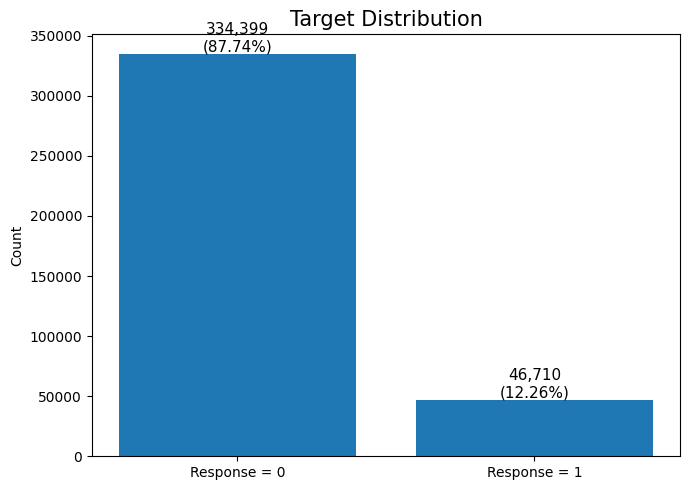

In [71]:
# ============================================================
# 5. Target(Response) 클래스 분포 확인
# ============================================================

response_count = (
    train["Response"]
    .value_counts()
    .sort_index()
)

response_ratio = (
    train["Response"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

response_summary = pd.DataFrame({
    "Count": response_count,
    "Ratio(%)": response_ratio
})

print("Response 분포")
display(response_summary.round(4))


# ============================================================
# 클래스 불균형 정도 확인
# ============================================================

negative_count = response_count.loc[0]
positive_count = response_count.loc[1]

imbalance_ratio = (
    negative_count / positive_count
)

print(
    f"Response=0 / Response=1 비율: "
    f"{imbalance_ratio:.2f} : 1"
)


# ============================================================
# 시각화
# ============================================================

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Response = 0", "Response = 1"],
    response_count.values
)

ax.set_title(
    "Target Distribution",
    fontsize=15
)

ax.set_ylabel("Count")

for bar, count, ratio in zip(
    bars,
    response_count.values,
    response_ratio.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({ratio:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()

## 6. 변수 구조 및 범주형 데이터 확인

각 변수의 고유값 수와 범주 구성을 확인한다.

`Region_Code`와 `Policy_Sales_Channel`은 숫자형으로 저장되어 있지만
값의 크기 자체에 연속적인 의미가 있는 변수가 아니라 지역 및 판매채널을 나타내는 식별 코드이므로
이후 범주형 변수로 처리한다.

In [72]:
# ============================================================
# 6. 변수별 고유값 수 확인
# ============================================================

unique_summary = pd.DataFrame({
    "dtype": train.dtypes,
    "Unique_Count": train.nunique()
})

display(unique_summary)


# ============================================================
# 주요 범주형 / 이진 변수 분포 확인
# ============================================================

check_cols = [
    "Gender",
    "Driving_License",
    "Previously_Insured",
    "Vehicle_Age",
    "Vehicle_Damage"
]

for col in check_cols:
    
    print("=" * 60)
    print(f"[{col}]")
    
    count = train[col].value_counts(dropna=False)
    ratio = train[col].value_counts(
        normalize=True,
        dropna=False
    ) * 100
    
    summary = pd.DataFrame({
        "Count": count,
        "Ratio(%)": ratio
    })
    
    display(summary.round(4))


# ============================================================
# 코드형 범주 변수 고유값 수
# ============================================================

print("=" * 60)

print(
    "Region_Code 고유값 수:",
    train["Region_Code"].nunique()
)

print(
    "Policy_Sales_Channel 고유값 수:",
    train["Policy_Sales_Channel"].nunique()
)

,dtype,Unique_Count
id,int64,381109
Gender,object,2
Age,int64,66
Driving_License,int64,2
Region_Code,float64,53
Previously_Insured,int64,2
Vehicle_Age,object,3
Vehicle_Damage,object,2
Annual_Premium,float64,48838
Policy_Sales_Channel,float64,155


[Gender]


,Count,Ratio(%)
Male,206089,54.076100
Female,175020,45.923900


[Driving_License]


,Count,Ratio(%)
1,380297,99.786900
0,812,0.213100


...

[Vehicle_Age]


,Count,Ratio(%)
1-2 Year,200316,52.561300
< 1 Year,164786,43.238500
> 2 Years,16007,4.200100


[Vehicle_Damage]


,Count,Ratio(%)
Yes,192413,50.487700
No,188696,49.512300


Region_Code 고유값 수: 53
Policy_Sales_Channel 고유값 수: 155


## 6-1. 식별자 변수 제거

`id`는 381,109개 행에서 모두 서로 다른 고유값을 가지는 단순 식별자이다.

고객을 구분하기 위한 번호일 뿐 보험 관심 여부를 설명하는 의미 있는 특성이 아니므로
EDA의 변수 관계 분석과 모델 학습에서는 제외한다.

단, 원본 데이터의 `id`는 최종 예측 결과 제출 시 필요하므로 원본 데이터는 보존하고
분석용 데이터셋에서만 제거한다.

In [73]:
# ============================================================
# 6-1. ID 변수 확인 및 분석 대상에서 제외
# ============================================================

print("Train 전체 행 수 :", len(train))
print("Train id 고유값 수:", train["id"].nunique())

print("Test 전체 행 수  :", len(test))
print("Test id 고유값 수 :", test["id"].nunique())


# ============================================================
# ID가 실제로 각 행을 고유하게 식별하는지 확인
# ============================================================

train_id_unique = (
    train["id"].nunique() == len(train)
)

test_id_unique = (
    test["id"].nunique() == len(test)
)

print("\nTrain ID 전체 고유 여부:", train_id_unique)
print("Test ID 전체 고유 여부 :", test_id_unique)


# ============================================================
# 원본은 보존하고 분석용 데이터에서만 ID 제거
# ============================================================

analysis_train = train.drop(
    columns=["id"]
).copy()

analysis_test = test.drop(
    columns=["id"]
).copy()


print("\nID 제거 전 Train shape:", train.shape)
print("ID 제거 후 Train shape:", analysis_train.shape)

print("ID 제거 전 Test shape :", test.shape)
print("ID 제거 후 Test shape :", analysis_test.shape)

Train 전체 행 수 : 381109
Train id 고유값 수: 381109
Test 전체 행 수  : 127037
Test id 고유값 수 : 127037

Train ID 전체 고유 여부: True
Test ID 전체 고유 여부 : True

ID 제거 전 Train shape: (381109, 12)
ID 제거 후 Train shape: (381109, 11)
ID 제거 전 Test shape : (127037, 11)
ID 제거 후 Test shape : (127037, 10)


## 7. 주요 범주형 변수와 보험 관심 여부의 관계

보험 관심 여부(`Response`)와 주요 범주형 변수의 관계를 확인한다.

단순 고객 수보다 각 그룹에서 `Response=1`이 차지하는 비율을 비교하여
어떤 특성을 가진 고객에게서 보험 관심도가 높게 나타나는지 살펴본다.

Vehicle_Damage별 Response


,Vehicle_Damage,Count,Response_Count,Response_Rate(%)
0,No,188696,982,0.520400
1,Yes,192413,45728,23.765500


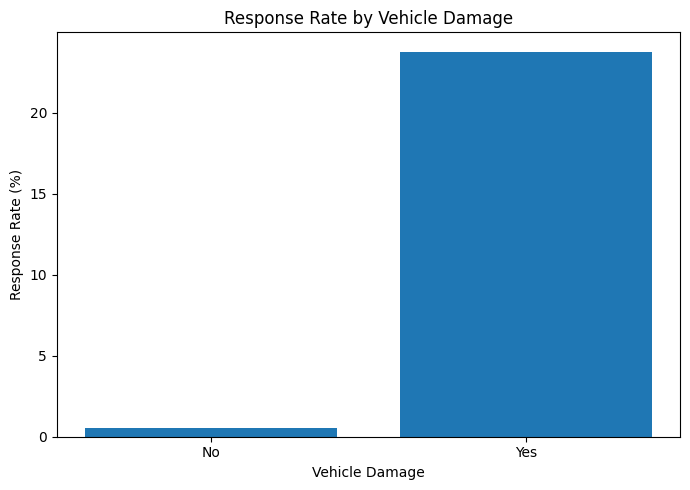


Previously_Insured별 Response


,Previously_Insured,Count,Response_Count,Response_Rate(%)
0,0,206481,46552,22.545400
1,1,174628,158,0.090500


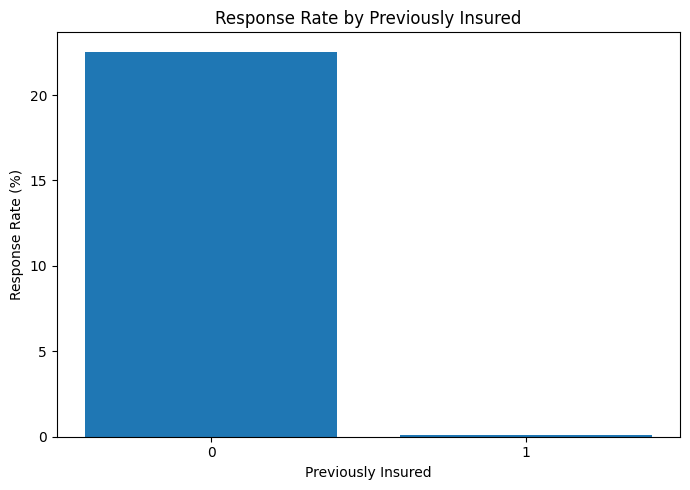


Vehicle_Age별 Response


,Vehicle_Age,Count,Response_Count,Response_Rate(%)
1,< 1 Year,164786,7202,4.370500
0,1-2 Year,200316,34806,17.375500
2,> 2 Years,16007,4702,29.374600


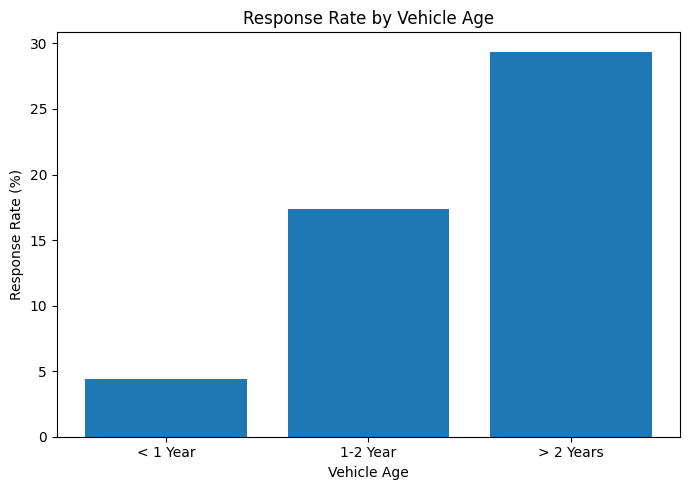

In [74]:
# ============================================================
# 7. 주요 범주형 변수별 Response 비율
# ============================================================

eda_categorical_cols = [
    "Vehicle_Damage",
    "Previously_Insured",
    "Vehicle_Age"
]


# ============================================================
# Response 비율 계산 함수
# ============================================================

def response_rate_table(data, column):

    result = (
        data.groupby(column)["Response"]
        .agg(
            Count="count",
            Response_Count="sum",
            Response_Rate="mean"
        )
        .reset_index()
    )

    result["Response_Rate(%)"] = (
        result["Response_Rate"] * 100
    )

    return result


# ============================================================
# 1. Vehicle_Damage
# ============================================================

vehicle_damage_summary = response_rate_table(
    train,
    "Vehicle_Damage"
)

print("Vehicle_Damage별 Response")
display(
    vehicle_damage_summary[
        [
            "Vehicle_Damage",
            "Count",
            "Response_Count",
            "Response_Rate(%)"
        ]
    ].round(4)
)


plt.figure(figsize=(7, 5))

plt.bar(
    vehicle_damage_summary["Vehicle_Damage"].astype(str),
    vehicle_damage_summary["Response_Rate(%)"]
)

plt.title("Response Rate by Vehicle Damage")
plt.xlabel("Vehicle Damage")
plt.ylabel("Response Rate (%)")

plt.tight_layout()
plt.show()


# ============================================================
# 2. Previously_Insured
# ============================================================

insured_summary = response_rate_table(
    train,
    "Previously_Insured"
)

print("\nPreviously_Insured별 Response")
display(
    insured_summary[
        [
            "Previously_Insured",
            "Count",
            "Response_Count",
            "Response_Rate(%)"
        ]
    ].round(4)
)


plt.figure(figsize=(7, 5))

plt.bar(
    insured_summary["Previously_Insured"].astype(str),
    insured_summary["Response_Rate(%)"]
)

plt.title("Response Rate by Previously Insured")
plt.xlabel("Previously Insured")
plt.ylabel("Response Rate (%)")

plt.tight_layout()
plt.show()


# ============================================================
# 3. Vehicle_Age
# ============================================================

vehicle_age_order = [
    "< 1 Year",
    "1-2 Year",
    "> 2 Years"
]

vehicle_age_summary = response_rate_table(
    train,
    "Vehicle_Age"
)

vehicle_age_summary["Vehicle_Age"] = pd.Categorical(
    vehicle_age_summary["Vehicle_Age"],
    categories=vehicle_age_order,
    ordered=True
)

vehicle_age_summary = (
    vehicle_age_summary
    .sort_values("Vehicle_Age")
)

print("\nVehicle_Age별 Response")
display(
    vehicle_age_summary[
        [
            "Vehicle_Age",
            "Count",
            "Response_Count",
            "Response_Rate(%)"
        ]
    ].round(4)
)


plt.figure(figsize=(7, 5))

plt.bar(
    vehicle_age_summary["Vehicle_Age"].astype(str),
    vehicle_age_summary["Response_Rate(%)"]
)

plt.title("Response Rate by Vehicle Age")
plt.xlabel("Vehicle Age")
plt.ylabel("Response Rate (%)")

plt.tight_layout()
plt.show()

## 8. 나이(Age)와 보험 관심도의 관계

나이별 고객 수와 `Response=1` 비율을 확인한다.

임의의 연령 구간으로 나누지 않고 실제 연령별 관심률을 비교하여
나이에 따른 보험 관심도의 변화 패턴을 살펴본다.

Age별 Response 요약


,Age,Count,Response_Count,Response_Rate,Response_Rate(%)
0,20,6232,171,0.027400,2.743900
1,21,16457,574,0.034900,3.487900
2,22,20964,763,0.036400,3.639600
3,23,24256,892,0.036800,3.677400
4,24,25960,913,0.035200,3.516900
5,25,20636,734,0.035600,3.556900
6,26,13535,484,0.035800,3.575900
7,27,10760,471,0.043800,4.377300
8,28,8974,617,0.068800,6.875400
9,29,7429,755,0.101600,10.162900


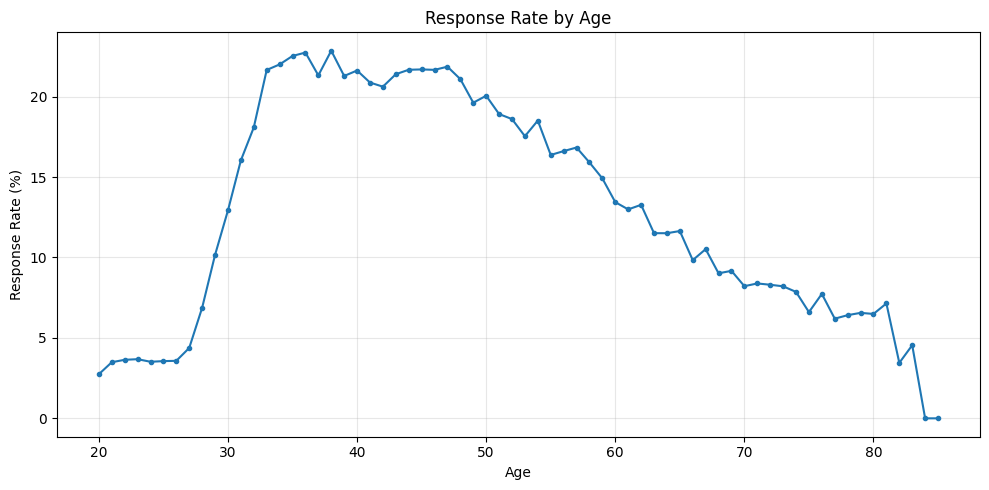


Response 비율 상위 10개 연령


,Age,Count,Response_Count,Response_Rate(%)
18,38,5710,1305,22.854600
16,36,5066,1152,22.739800
15,35,4936,1112,22.528400
14,34,4895,1077,22.002000
27,47,7351,1607,21.861000
25,45,8183,1775,21.691300
24,44,8357,1811,21.670500
26,46,7879,1707,21.665200
13,33,5010,1085,21.656700
20,40,7168,1550,21.623900


In [75]:
# ============================================================
# 8. Age별 Response 비율 확인
# ============================================================

age_summary = (
    train.groupby("Age")["Response"]
    .agg(
        Count="count",
        Response_Count="sum",
        Response_Rate="mean"
    )
    .reset_index()
)

age_summary["Response_Rate(%)"] = (
    age_summary["Response_Rate"] * 100
)

print("Age별 Response 요약")
display(age_summary.head(10).round(4))


# ============================================================
# Age별 Response Rate 시각화
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    age_summary["Age"],
    age_summary["Response_Rate(%)"],
    marker="o",
    markersize=3
)

plt.title("Response Rate by Age")
plt.xlabel("Age")
plt.ylabel("Response Rate (%)")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 관심률이 가장 높은 연령 확인
# ============================================================

top_age_response = (
    age_summary
    .sort_values(
        "Response_Rate(%)",
        ascending=False
    )
    .head(10)
)

print("\nResponse 비율 상위 10개 연령")
display(
    top_age_response[
        [
            "Age",
            "Count",
            "Response_Count",
            "Response_Rate(%)"
        ]
    ].round(4)
)

In [76]:
display(
    top_age_response[
        ["Age", "Count", "Response_Count", "Response_Rate(%)"]
    ]
    .reset_index(drop=True)
    .round(4)
)

,Age,Count,Response_Count,Response_Rate(%)
0,38,5710,1305,22.854600
1,36,5066,1152,22.739800
2,35,4936,1112,22.528400
3,34,4895,1077,22.002000
4,47,7351,1607,21.861000
5,45,8183,1775,21.691300
6,44,8357,1811,21.670500
7,46,7879,1707,21.665200
8,33,5010,1085,21.656700
9,40,7168,1550,21.623900


## 9. Annual_Premium과 Vintage 분포 탐색

연보험료(`Annual_Premium`)와 고객 가입 기간(`Vintage`)이
보험 관심 여부에 따라 다른 분포를 보이는지 확인한다.

Response별 수치형 변수 요약


Annual_Premium                              Vintage             \
                   mean       median          std       mean     median   
Response                                                                  
0          30419.160000 31504.000000 16998.290000 154.380000 154.000000   
1          31604.090000 33002.000000 18646.510000 154.110000 154.000000   

                    
               std  
Response            
0        83.660000  
1        83.740000

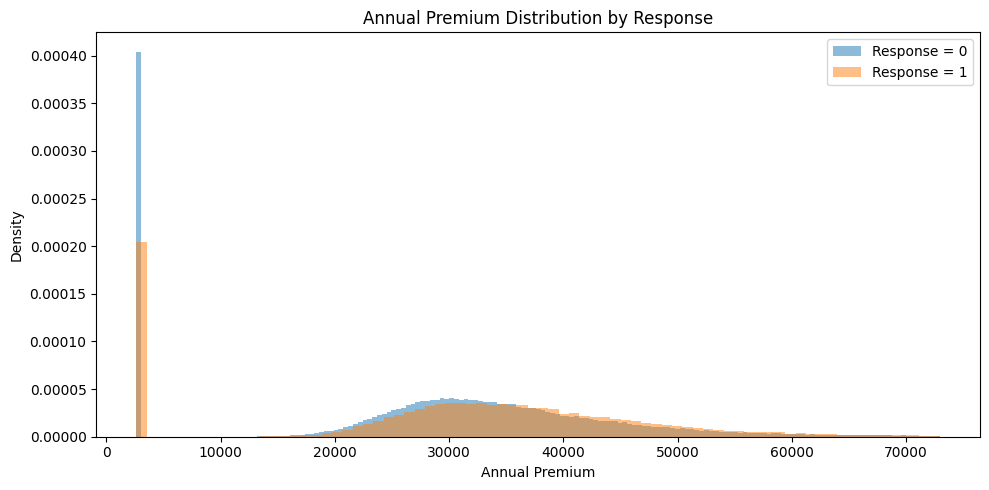

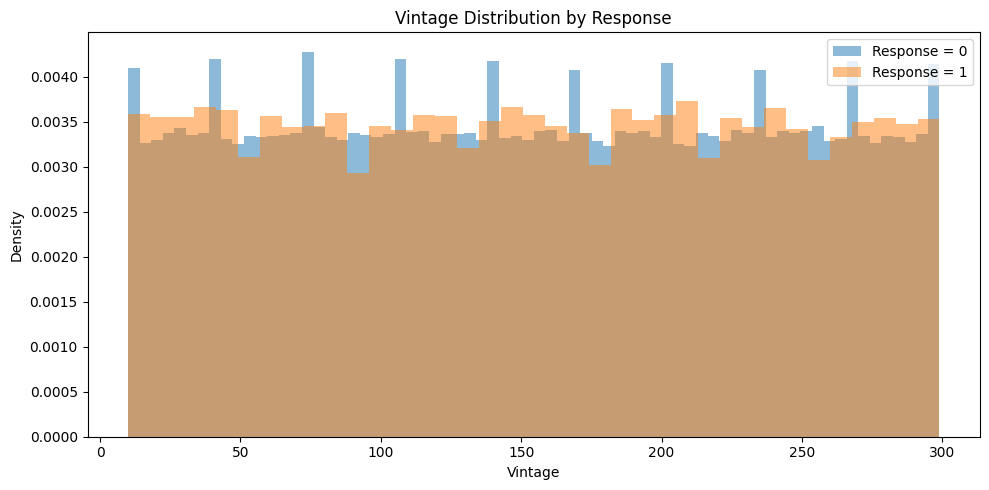

In [77]:
# ============================================================
# 9. Annual_Premium / Vintage 탐색
# ============================================================

# Response별 기본 통계
continuous_summary = (
    train.groupby("Response")[
        ["Annual_Premium", "Vintage"]
    ]
    .agg(["mean", "median", "std"])
)

print("Response별 수치형 변수 요약")
display(continuous_summary.round(2))


# ============================================================
# Annual_Premium 분포
# 시각화에서만 99% 분위수까지 표시
# 실제 데이터는 제거하지 않음
# ============================================================

premium_99 = train["Annual_Premium"].quantile(0.99)

premium_0 = train.loc[
    (train["Response"] == 0) &
    (train["Annual_Premium"] <= premium_99),
    "Annual_Premium"
]

premium_1 = train.loc[
    (train["Response"] == 1) &
    (train["Annual_Premium"] <= premium_99),
    "Annual_Premium"
]

plt.figure(figsize=(10, 5))

plt.hist(
    premium_0,
    bins="fd",
    density=True,
    alpha=0.5,
    label="Response = 0"
)

plt.hist(
    premium_1,
    bins="fd",
    density=True,
    alpha=0.5,
    label="Response = 1"
)

plt.title("Annual Premium Distribution by Response")
plt.xlabel("Annual Premium")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# Vintage 분포
# ============================================================

vintage_0 = train.loc[
    train["Response"] == 0,
    "Vintage"
]

vintage_1 = train.loc[
    train["Response"] == 1,
    "Vintage"
]

plt.figure(figsize=(10, 5))

plt.hist(
    vintage_0,
    bins="fd",
    density=True,
    alpha=0.5,
    label="Response = 0"
)

plt.hist(
    vintage_1,
    bins="fd",
    density=True,
    alpha=0.5,
    label="Response = 1"
)

plt.title("Vintage Distribution by Response")
plt.xlabel("Vintage")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Phi_K를 이용한 변수 간 연관성 분석

데이터에는 연속형 변수와 범주형 변수가 함께 존재하므로
변수 간 관계를 종합적으로 확인하기 위해 Phi_K 상관계수를 사용한다.

Phi_K는 범주형·연속형 변수가 혼합된 데이터에서 사용할 수 있으며,
비선형 관계까지 확인할 수 있다.

- 0에 가까울수록 연관성이 낮음
- 1에 가까울수록 연관성이 강함

`id`는 단순 식별자이므로 분석에서 제외한다.

In [78]:
%pip install phik -q

Note: you may need to restart the kernel to use updated packages.


Response와의 Phi_K


,Phi_K_with_Response
Vehicle_Damage,0.528400
Previously_Insured,0.510600
Policy_Sales_Channel,0.324800
Age,0.299400
Region_Code,0.166100
Vehicle_Age,0.134400
Gender,0.082200
Annual_Premium,0.026000
Driving_License,0.015600
Vintage,0.004500


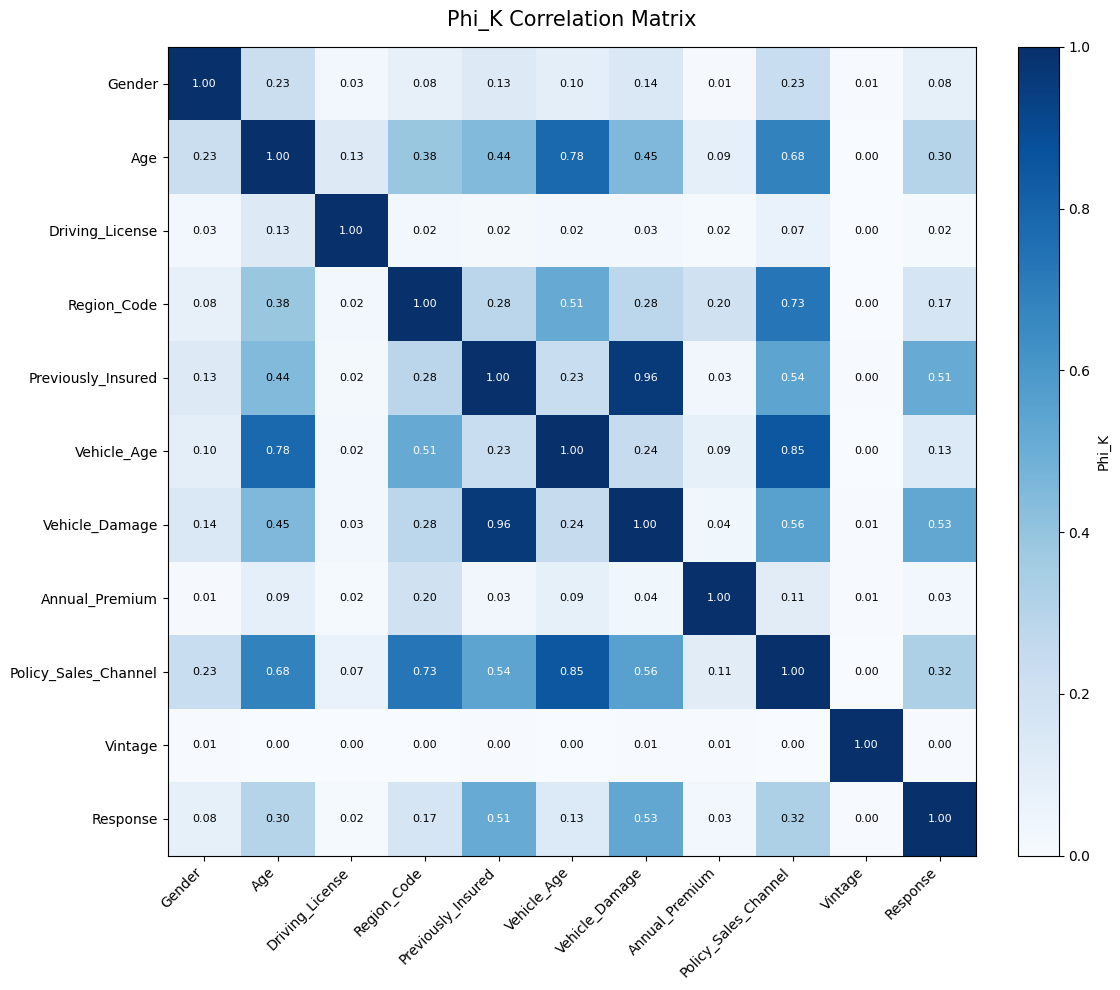

In [79]:
# ============================================================
# 10. Phi_K 연관성 분석
# ============================================================

import phik
import matplotlib.pyplot as plt


# ============================================================
# id 제외
# ============================================================

phik_data = train.drop(columns=["id"]).copy()


# ============================================================
# 실제 연속형 변수만 지정
#
# Region_Code, Policy_Sales_Channel은 숫자로 저장되어 있지만
# 범주 코드이므로 interval_cols에 포함하지 않음
#
# Driving_License, Previously_Insured, Response도
# 이진 범주형 변수로 처리
# ============================================================

interval_cols = [
    "Age",
    "Annual_Premium",
    "Vintage"
]


# ============================================================
# Phi_K Matrix 계산
# ============================================================

phik_matrix = phik_data.phik_matrix(
    interval_cols=interval_cols
)


# ============================================================
# Response와의 연관성 확인
# ============================================================

response_phik = (
    phik_matrix["Response"]
    .drop("Response")
    .sort_values(ascending=False)
    .to_frame("Phi_K_with_Response")
)

print("Response와의 Phi_K")
display(response_phik.round(4))


# ============================================================
# 전체 Phi_K Heatmap
# ============================================================

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    phik_matrix,
    cmap="Blues",
    vmin=0,
    vmax=1
)

# 축 이름
ax.set_xticks(range(len(phik_matrix.columns)))
ax.set_xticklabels(
    phik_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(range(len(phik_matrix.index)))
ax.set_yticklabels(phik_matrix.index)


# ============================================================
# 각 칸에 Phi_K 값 표시
# ============================================================

for i in range(len(phik_matrix.index)):
    for j in range(len(phik_matrix.columns)):

        value = phik_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value >= 0.5 else "black"
        )


# ============================================================
# Colorbar / 제목
# ============================================================

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label("Phi_K")

ax.set_title(
    "Phi_K Correlation Matrix",
    fontsize=15,
    pad=15
)

plt.tight_layout()
plt.show()

## 11. 연속형 변수와 Response의 통계적 관계 검정

이진형 Target인 `Response`와 연속형 변수인
`Annual_Premium`, `Vintage`의 관계 검정을 통해 유의한지 판단

- 상관계수 `r`: 관계의 방향과 강도
- `p-value`: 통계적으로 유의한 관계인지 판단
- 일반적으로 `p < 0.05`이면 통계적으로 유의하다고 판단한다.

단, 표본 수가 매우 큰 경우 매우 작은 관계도 통계적으로 유의하게 나타날 수 있으므로
`p-value`와 함께 상관계수의 크기도 함께 해석한다.

In [80]:
# ============================================================
# 11. P-value
# ============================================================

from scipy.stats import pointbiserialr

cols = [
    "Annual_Premium",
    "Vintage",
    "Driving_License"
]

for col in cols:
    r, p = pointbiserialr(
        train["Response"],
        train[col]
    )

    print(f"{col}")
    print(f"  p-value          : {p:.10g}")

    if p < 0.05:
        print("  결과             : 통계적으로 유의함 (p < 0.05)")
    else:
        print("  결과             : 통계적으로 유의하지 않음 (p >= 0.05)")

    print()

Annual_Premium
  p-value          : 3.72231514e-44
  결과             : 통계적으로 유의함 (p < 0.05)

Vintage
  p-value          : 0.5167036523
  결과             : 통계적으로 유의하지 않음 (p >= 0.05)

Driving_License
  p-value          : 3.625834382e-10
  결과             : 통계적으로 유의함 (p < 0.05)



## 12. Vintage 변수 제거

EDA 결과 `Vintage`는 보험 관심 여부와의 관계가 매우 낮게 나타났다.

- Response 그룹 간 평균과 중앙값 차이가 거의 없음
- p-value: 0.5167 → 통계적으로 유의하지 않음
- Response와의 Phi_K: 0.0045

따라서 분석 복잡도를 줄이고 의미 있는 변수에 집중하기 위해
`Vintage`를 최종 입력 변수에서 제외한다.

In [81]:
# ============================================================
# 12. Vintage 변수 제거
# ============================================================

analysis_train = analysis_train.drop(
    columns=["Vintage"]
).copy()

analysis_test = analysis_test.drop(
    columns=["Vintage"]
).copy()


print("Vintage 제거 후 Train shape:", analysis_train.shape)
print("Vintage 제거 후 Test shape :", analysis_test.shape)

print("\n최종 분석 변수")
print(analysis_train.columns.tolist())

Vintage 제거 후 Train shape: (381109, 10)
Vintage 제거 후 Test shape : (127037, 9)

최종 분석 변수
['Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Response']


## 13. 최종 입력 변수 구성 및 이진 변수 변환

최종 모델에 사용할 변수를 역할에 따라 구분한다.

- 수치형: Age, Annual_Premium
- 이진형: Gender, Driving_License, Previously_Insured, Vehicle_Damage
- 범주형: Region_Code, Vehicle_Age, Policy_Sales_Channel

`Gender`와 `Vehicle_Damage`는 문자열로 저장되어 있으므로 0/1로 변환한다.

`Region_Code`와 `Policy_Sales_Channel`은 숫자형으로 저장되어 있지만
크기 자체에 순서나 연속적인 의미가 없는 코드값이므로 범주형으로 처리한다.

In [82]:
# ============================================================
# 13. 최종 입력 변수 구성
# ============================================================

model_train = analysis_train.copy()
model_test = analysis_test.copy()


# ============================================================
# 문자열 이진 변수 0/1 변환
# ============================================================

gender_map = {
    "Female": 0,
    "Male": 1
}

damage_map = {
    "No": 0,
    "Yes": 1
}


model_train["Gender"] = (
    model_train["Gender"]
    .map(gender_map)
)

model_test["Gender"] = (
    model_test["Gender"]
    .map(gender_map)
)


model_train["Vehicle_Damage"] = (
    model_train["Vehicle_Damage"]
    .map(damage_map)
)

model_test["Vehicle_Damage"] = (
    model_test["Vehicle_Damage"]
    .map(damage_map)
)


# ============================================================
# 변수 역할 정의
# ============================================================

numeric_cols = [
    "Age",
    "Annual_Premium"
]

binary_cols = [
    "Gender",
    "Driving_License",
    "Previously_Insured",
    "Vehicle_Damage"
]

categorical_cols = [
    "Region_Code",
    "Vehicle_Age",
    "Policy_Sales_Channel"
]


# ============================================================
# 확인
# ============================================================

print("수치형 변수:")
print(numeric_cols)

print("\n이진형 변수:")
print(binary_cols)

print("\n범주형 변수:")
print(categorical_cols)

print("\nGender 변환 결과:")
print(model_train["Gender"].value_counts().sort_index())

print("\nVehicle_Damage 변환 결과:")
print(model_train["Vehicle_Damage"].value_counts().sort_index())

수치형 변수:
['Age', 'Annual_Premium']

이진형 변수:
['Gender', 'Driving_License', 'Previously_Insured', 'Vehicle_Damage']

범주형 변수:
['Region_Code', 'Vehicle_Age', 'Policy_Sales_Channel']

Gender 변환 결과:
0    175020
1    206089
Name: Gender, dtype: int64

Vehicle_Damage 변환 결과:
0    188696
1    192413
Name: Vehicle_Damage, dtype: int64


## 14. 학습/검증 데이터 분리

최종 입력 변수와 Target(`Response`)을 분리한 뒤
학습용 데이터와 검증용 데이터로 나눈다.

Target 클래스 비율이 불균형하므로 `stratify=y`를 사용해
Train과 Validation에서 클래스 비율이 동일하게 유지되도록 한다.

In [83]:
# ============================================================
# 14. X / y 구성
# ============================================================

X = model_train.drop(
    columns=["Response"]
).copy()

y = model_train["Response"].copy()

X_test_final = model_test.copy()


print("X shape      :", X.shape)
print("y shape      :", y.shape)
print("X_test shape :", X_test_final.shape)


# ============================================================
# Train / Validation Split
# ============================================================

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)


print("\nTrain shape :", X_train.shape)
print("Valid shape :", X_valid.shape)


# ============================================================
# 클래스 비율 확인
# ============================================================

split_summary = pd.DataFrame({
    "전체": y.value_counts(normalize=True).sort_index(),
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Validation": y_valid.value_counts(normalize=True).sort_index()
}) * 100

print("\nResponse 비율(%)")
display(split_summary.round(4))

X shape      : (381109, 9)
y shape      : (381109,)
X_test shape : (127037, 9)

Train shape : (304887, 9)
Valid shape : (76222, 9)

Response 비율(%)


,전체,Train,Validation
0,87.743700,87.743700,87.743700
1,12.256300,12.256300,12.256300


## 15. 전처리 파이프라인 구성

모델 특성에 따라 전처리 방식을 구분한다.

- Logistic Regression:
  수치형 변수의 스케일 차이에 영향을 받기 때문에 StandardScaler 적용
- Tree 기반 모델:
  수치형 변수의 스케일 영향을 거의 받지 않으므로 원본 값을 그대로 사용
- 이진형 변수:
  이미 0/1 형태이므로 그대로 사용
- 범주형 변수:
  순서 의미가 없으므로 One-Hot Encoding 적용

전처리 과정은 `ColumnTransformer`와 `Pipeline` 내부에서 수행하여
학습 데이터에만 fit되도록 하고 데이터 누수를 방지한다.

In [84]:
# ============================================================
# 15. 전처리 파이프라인 구성
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)


# ============================================================
# Logistic Regression용 전처리
# ============================================================

logistic_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_cols
        ),
        (
            "binary",
            "passthrough",
            binary_cols
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_cols
        )
    ]
)


# ============================================================
# Tree 계열 모델용 전처리
# ============================================================

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_cols
        ),
        (
            "binary",
            "passthrough",
            binary_cols
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_cols
        )
    ]
)


print("Logistic 전처리 구성 완료")
print("Tree 계열 전처리 구성 완료")

Logistic 전처리 구성 완료
Tree 계열 전처리 구성 완료


## 16. 교차검증 및 평가 지표 설정

Target 클래스가 약 7.16:1로 불균형하므로 단순 Accuracy보다는
소수 클래스인 `Response=1`을 얼마나 잘 구분하는지 확인할 수 있는 지표를 중심으로 평가한다.

주요 평가 지표는 다음과 같다.

- **F1 Score**: Precision과 Recall의 균형
- **ROC-AUC**: 전체적인 분류 순위 성능
- **Average Precision(AP)**: 불균형 데이터에서 Positive 클래스의 예측 성능 평가

교차검증은 각 Fold의 클래스 비율을 유지하기 위해
`StratifiedKFold`를 사용한다.

모델 비교 단계에서는 동일한 5-Fold 기준을 적용한다.

In [85]:
# ============================================================
# 16. 교차검증 및 평가 지표 설정
# ============================================================

from sklearn.model_selection import StratifiedKFold


# ============================================================
# Stratified 5-Fold
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================
# 모델 비교용 평가 지표
# ============================================================

scoring = {
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "AP": "average_precision"
}


print("교차검증:", cv)
print("\n평가 지표:")
for name, scorer in scoring.items():
    print(f"- {name}: {scorer}")

교차검증: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

평가 지표:
- F1: f1
- ROC_AUC: roc_auc
- AP: average_precision


## 17. 모델 비교 결과

초기 전체 변수(Vintage 포함)를 사용하여 6개 분류 모델을 비교하였다.

모델 비교 단계에서는 클래스 불균형의 영향을 고려하여
ROC-AUC와 Average Precision(AP)을 중심으로 성능을 비교하였다.

하이퍼파라미터 탐색은 실행 시간이 오래 걸리는 과정이므로,
공유 노트북에서는 기존 실험 결과를 보존하여 사용한다.

### 모델 선정

XGBoost, LightGBM, Gradient Boosting의 F1 성능은 매우 유사하게 나타났다.

그중 XGBoost가 ROC-AUC와 AP에서 가장 높은 성능을 보여
최종 모델로 선정하였다.

9개 입력 변수를 이용해 XGBoost를 학습하고,
OOF 예측을 기반으로 최종 Threshold를 결정한다.

In [86]:
# ============================================================
# 17. 기존 모델 비교 결과
# 초기 전체 Feature(Vintage 포함) 기준
# 기존 실행 결과를 재사용
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "XGBoost",
        "LightGBM",
        "Gradient Boosting",
        "Logistic Regression",
        "Random Forest",
        "Decision Tree"
    ],

    "F1": [
        0.4592,
        0.4592,
        0.4590,
        0.4534,
        0.4260,
        0.3022
    ],

    "ROC_AUC": [
        0.8582,
        0.8580,
        0.8577,
        0.8492,
        0.8366,
        0.8315
    ],

    "AP": [
        0.3717,
        0.3715,
        0.3703,
        0.3375,
        0.3067,
        0.2981
    ]
})


model_comparison = (
    model_comparison
    .sort_values(
        ["AP", "ROC_AUC"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(model_comparison)

,Model,F1,ROC_AUC,AP
0,XGBoost,0.459200,0.858200,0.371700
1,LightGBM,0.459200,0.858000,0.371500
2,Gradient Boosting,0.459000,0.857700,0.370300
3,Logistic Regression,0.453400,0.849200,0.337500
4,Random Forest,0.426000,0.836600,0.306700
5,Decision Tree,0.302200,0.831500,0.298100


## 18. 최종 XGBoost 학습 및 OOF Threshold 최적화

초기 모델 비교에서 가장 좋은 성능을 보인 XGBoost를 최종 모델로 선정한다.

하이퍼파라미터는 기존 탐색에서 얻은 최적값을 사용하며,
EDA에서 제외한 `Vintage`를 반영하여 최종 9개 입력 변수로 다시 학습한다.

분류 Threshold는 임의로 0.5를 사용하지 않고,
Train 데이터의 5-Fold OOF(Out-of-Fold) 예측에서 F1 Score가 최대가 되는 지점을 선택한다.

이렇게 결정된 Threshold는 이후 Validation 데이터에 고정 적용한다.

In [87]:
# ============================================================
# 18. 최종 XGBoost + OOF Threshold 최적화
# ============================================================

import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from xgboost import XGBClassifier
RANDOM_STATE = 42

# ============================================================
# 1. 기존 튜닝에서 선정된 XGBoost 최적 파라미터
# ============================================================

final_xgb_params = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",

    "subsample": 0.9,
    "scale_pos_weight": 1.0,

    "reg_lambda": 10,
    "reg_alpha": 0.5,

    "n_estimators": 500,
    "min_child_weight": 20,
    "max_depth": 6,

    "learning_rate": 0.05,
    "gamma": 0.1,
    "colsample_bytree": 0.6,

    "random_state": RANDOM_STATE,
    "n_jobs": 1
}


# ============================================================
# 2. 최종 Pipeline
# ============================================================

final_xgb_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),
    (
        "model",
        XGBClassifier(
            **final_xgb_params
        )
    )
])


# ============================================================
# 3. 5-Fold OOF 확률 예측
# ============================================================

oof_prob_xgb = cross_val_predict(
    final_xgb_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]


# ============================================================
# 4. OOF에서 F1 최대 Threshold 탐색
# ============================================================

precision_oof, recall_oof, thresholds_oof = (
    precision_recall_curve(
        y_train,
        oof_prob_xgb
    )
)

f1_oof = (
    2
    * precision_oof[:-1]
    * recall_oof[:-1]
    /
    (
        precision_oof[:-1]
        + recall_oof[:-1]
        + 1e-10
    )
)

best_idx = np.argmax(f1_oof)

final_threshold = thresholds_oof[best_idx]

oof_precision = precision_oof[best_idx]
oof_recall = recall_oof[best_idx]
oof_f1 = f1_oof[best_idx]


# ============================================================
# 5. OOF ROC-AUC / AP
# ============================================================

oof_auc = roc_auc_score(
    y_train,
    oof_prob_xgb
)

oof_ap = average_precision_score(
    y_train,
    oof_prob_xgb
)


# ============================================================
# 6. 결과 확인
# ============================================================

print("===== OOF Threshold Optimization =====")

print(
    f"Best Threshold : {final_threshold:.6f}"
)

print(
    f"Precision      : {oof_precision:.6f}"
)

print(
    f"Recall         : {oof_recall:.6f}"
)

print(
    f"F1             : {oof_f1:.6f}"
)

print(
    f"ROC-AUC        : {oof_auc:.6f}"
)

print(
    f"AP             : {oof_ap:.6f}"
)


# ============================================================
# 7. 전체 Train 데이터로 최종 학습
# ============================================================

final_xgb_model.fit(
    X_train,
    y_train
)


# ============================================================
# 8. Validation 확률 저장
# ============================================================

valid_prob_xgb = final_xgb_model.predict_proba(
    X_valid
)[:, 1]

print("\n최종 XGBoost 학습 완료")

===== OOF Threshold Optimization =====
Best Threshold : 0.222612
Precision      : 0.328060
Recall         : 0.769188
F1             : 0.459951
ROC-AUC        : 0.858311
AP             : 0.371018

최종 XGBoost 학습 완료


### 18-1. Soft Voting 앙상블 추가 실험

단일 XGBoost보다 성능을 추가로 개선할 수 있는지 확인하기 위해
상위 성능 모델인 XGBoost, LightGBM, Gradient Boosting을 결합한
Soft Voting 앙상블을 추가로 실험하였다.

앙상블은 일부 평가 지표에서 소폭 개선되었으나,
성능 향상 폭에 비해 여러 모델을 동시에 운영해야 하는 복잡성이 증가하였다.

따라서 최종 모델은 단일 XGBoost로 유지하였다.

※ 해당 앙상블 결과는 모델 비교 과정에서 수행했던 기존 실험 결과이다.

### 최종 모델 선정

모델 비교와 추가 앙상블 실험을 종합한 결과,
성능과 모델 운영 복잡성의 균형을 고려하여
단일 XGBoost를 최종 모델로 선정하였다.

이후 평가는 Vintage를 제외한 9개 입력 변수로 재학습한
XGBoost와 OOF에서 결정한 Threshold를 기준으로 수행한다.

In [88]:
# ============================================================
# 18-1. Soft Voting 앙상블 기존 실험 결과
# 기존 전체 Feature(Vintage 포함) 기준
# ============================================================

ensemble_result = pd.DataFrame({
    "Evaluation": [
        "OOF",
        "Validation"
    ],

    "Threshold": [
        0.3778295,
        0.3778295
    ],

    "Precision": [
        0.331295,
        0.331210
    ],

    "Recall": [
        0.751151,
        0.751338
    ],

    "F1": [
        0.459797,
        0.459750
    ],

    "ROC_AUC": [
        0.858415,
        0.858817
    ],

    "AP": [
        0.372051,
        0.372469
    ]
})

display(
    ensemble_result.round(6)
)

,Evaluation,Threshold,Precision,Recall,F1,ROC_AUC,AP
0,OOF,0.377830,0.331295,0.751151,0.459797,0.858415,0.372051
1,Validation,0.377830,0.331210,0.751338,0.459750,0.858817,0.372469


## 19. Validation 데이터 최종 평가

Train 데이터의 OOF 예측에서 결정한 Threshold(`0.222612`)를
Validation 데이터에 그대로 적용하여 최종 일반화 성능을 평가한다.

Validation 데이터에서는 Threshold를 다시 조정하지 않고,
Precision, Recall, F1, ROC-AUC, AP와 Confusion Matrix를 확인한다.

===== Validation Final Performance =====


,Metric,Value
0,Threshold,0.222612
1,Precision,0.328498
2,Recall,0.768358
3,F1,0.460231
4,ROC-AUC,0.858701
5,AP,0.372132


Confusion Matrix
[[52207 14673]
 [ 2164  7178]]

TN: 52,207
FP: 14,673
FN: 2,164
TP: 7,178


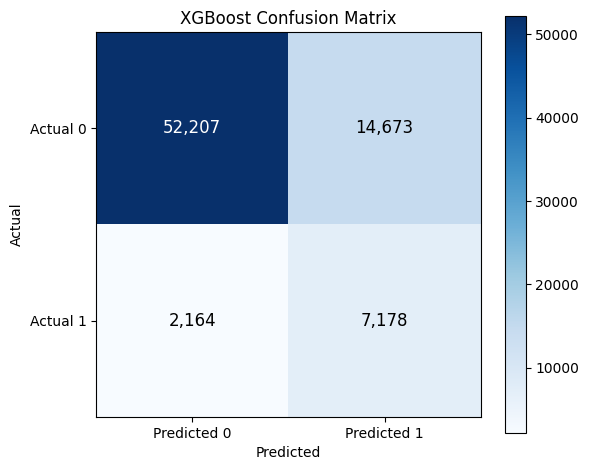


Classification Report
              precision    recall  f1-score   support

           0     0.9602    0.7806    0.8611     66880
           1     0.3285    0.7684    0.4602      9342

    accuracy                         0.7791     76222
   macro avg     0.6443    0.7745    0.6607     76222
weighted avg     0.8828    0.7791    0.8120     76222



In [89]:
# ============================================================
# 19. Validation 최종 평가
# ============================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. OOF에서 결정한 Threshold 고정 적용
# ============================================================

valid_pred_xgb = (
    valid_prob_xgb >= final_threshold
).astype(int)


# ============================================================
# 2. 평가 지표 계산
# ============================================================

valid_precision = precision_score(
    y_valid,
    valid_pred_xgb
)

valid_recall = recall_score(
    y_valid,
    valid_pred_xgb
)

valid_f1 = f1_score(
    y_valid,
    valid_pred_xgb
)

valid_auc = roc_auc_score(
    y_valid,
    valid_prob_xgb
)

valid_ap = average_precision_score(
    y_valid,
    valid_prob_xgb
)


validation_result = pd.DataFrame({
    "Metric": [
        "Threshold",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "AP"
    ],
    "Value": [
        final_threshold,
        valid_precision,
        valid_recall,
        valid_f1,
        valid_auc,
        valid_ap
    ]
})


print("===== Validation Final Performance =====")
display(validation_result.round(6))


# ============================================================
# 3. Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_valid,
    valid_pred_xgb
)

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix")
print(cm)

print(f"\nTN: {tn:,}")
print(f"FP: {fp:,}")
print(f"FN: {fn:,}")
print(f"TP: {tp:,}")


# ============================================================
# 4. Confusion Matrix 시각화
# ============================================================

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(
    cm,
    cmap="Blues"
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Predicted 0",
    "Predicted 1"
])

ax.set_yticklabels([
    "Actual 0",
    "Actual 1"
])

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

ax.set_title(
    "XGBoost Confusion Matrix"
)

for i in range(2):
    for j in range(2):

        value = cm[i, j]

        ax.text(
            j,
            i,
            f"{value:,}",
            ha="center",
            va="center",
            fontsize=12,
            color="white"
            if value > cm.max() / 2
            else "black"
        )

plt.colorbar(
    im,
    ax=ax
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. Classification Report
# ============================================================

print("\nClassification Report")

print(
    classification_report(
        y_valid,
        valid_pred_xgb,
        digits=4
    )
)

## 20. ROC Curve 및 Precision-Recall Curve

최종 XGBoost의 확률 예측 성능을 ROC Curve와
Precision-Recall Curve를 통해 확인한다.

- ROC-AUC는 전체적인 클래스 구분 능력을 평가한다.
- AP(Average Precision)는 클래스 불균형 환경에서 Positive 클래스의
  Precision-Recall 성능을 요약한다.

또한 OOF에서 결정한 F1 최적 Threshold의 실제 운영 지점을
곡선 위에 함께 표시한다.

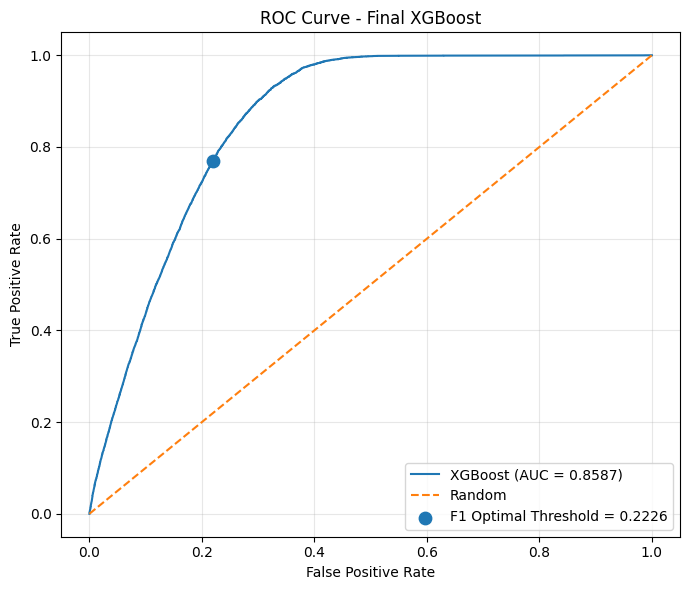

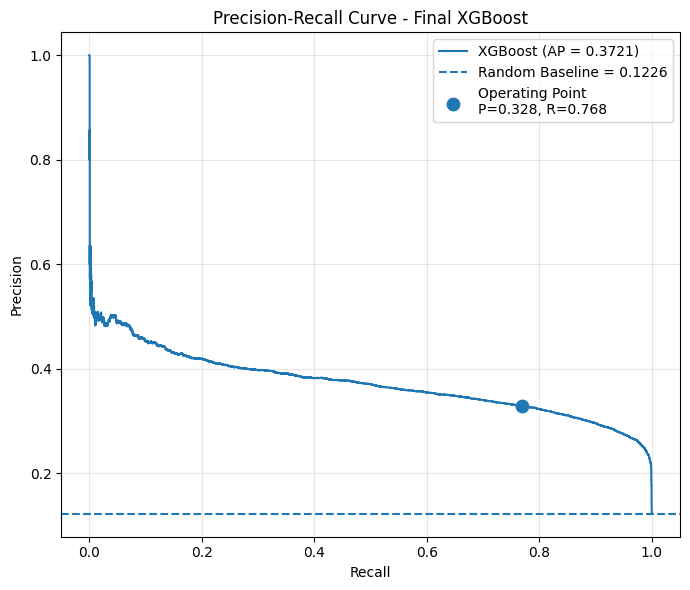

In [90]:
# ============================================================
# 20. ROC Curve / Precision-Recall Curve
# ============================================================

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)

import matplotlib.pyplot as plt


# ============================================================
# 1. ROC Curve
# ============================================================

fpr, tpr, roc_thresholds = roc_curve(
    y_valid,
    valid_prob_xgb
)

# 현재 threshold와 가장 가까운 ROC 지점
roc_idx = np.argmin(
    np.abs(
        roc_thresholds - final_threshold
    )
)


plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {valid_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.scatter(
    fpr[roc_idx],
    tpr[roc_idx],
    s=80,
    zorder=5,
    label=f"F1 Optimal Threshold = {final_threshold:.4f}"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - Final XGBoost"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ============================================================
# 2. Precision-Recall Curve
# ============================================================

pr_precision, pr_recall, pr_thresholds = (
    precision_recall_curve(
        y_valid,
        valid_prob_xgb
    )
)


# 현재 threshold에 가장 가까운 PR 지점
pr_idx = np.argmin(
    np.abs(
        pr_thresholds - final_threshold
    )
)


# Positive 비율 = Random baseline
positive_rate = y_valid.mean()


plt.figure(figsize=(7, 6))

plt.plot(
    pr_recall,
    pr_precision,
    label=f"XGBoost (AP = {valid_ap:.4f})"
)

plt.axhline(
    positive_rate,
    linestyle="--",
    label=f"Random Baseline = {positive_rate:.4f}"
)

plt.scatter(
    pr_recall[pr_idx],
    pr_precision[pr_idx],
    s=80,
    zorder=5,
    label=(
        f"Operating Point\n"
        f"P={valid_precision:.3f}, "
        f"R={valid_recall:.3f}"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve - Final XGBoost"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

## 21. Recall 95% 운영점 비교

현재 최종 Threshold는 OOF 데이터에서 F1 Score가 최대가 되도록 선택하였다.

하지만 실제 관심 고객을 최대한 놓치지 않는 것을 우선한다면
Threshold를 낮춰 Recall을 더 높일 수 있다.

따라서 동일한 XGBoost 모델에서 Recall 95%를 목표로 하는 Threshold를
OOF 데이터에서 추가로 설정하고, 기존 F1 최적 운영점과 비교한다.

이를 통해 Recall을 극단적으로 높였을 때 발생하는
Precision 감소와 상담 후보 증가의 Trade-off를 확인한다.

In [91]:
# ============================================================
# 21. F1 최적점 vs Recall 95% 운영점 비교
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ============================================================
# 1. OOF에서 Recall 95% 이상 Threshold 탐색
# ============================================================

target_recall = 0.95

precision_oof_95, recall_oof_95, thresholds_oof_95 = (
    precision_recall_curve(
        y_train,
        oof_prob_xgb
    )
)

# thresholds와 길이를 맞춤
p = precision_oof_95[:-1]
r = recall_oof_95[:-1]
t = thresholds_oof_95


# Recall 95% 이상인 지점
mask = r >= target_recall

candidate_idx = np.where(mask)[0]


# Recall 95% 이상을 만족하는 지점 중
# Precision이 가장 높은 Threshold 선택
best_95_idx = candidate_idx[
    np.argmax(p[candidate_idx])
]

threshold_95 = t[best_95_idx]


print(
    f"OOF Recall 95% Threshold: "
    f"{threshold_95:.6f}"
)


# ============================================================
# 2. Validation에 Threshold 고정 적용
# ============================================================

valid_pred_95 = (
    valid_prob_xgb >= threshold_95
).astype(int)


precision_95 = precision_score(
    y_valid,
    valid_pred_95
)

recall_95 = recall_score(
    y_valid,
    valid_pred_95
)

f1_95 = f1_score(
    y_valid,
    valid_pred_95
)


# ============================================================
# 3. 상담 후보 수
# ============================================================

candidate_final = valid_pred_xgb.sum()
candidate_95 = valid_pred_95.sum()


# ============================================================
# 4. 비교표
# ============================================================

operating_comparison = pd.DataFrame({
    "Operating_Point": [
        "F1 Optimal",
        "Recall 95%"
    ],

    "Threshold": [
        final_threshold,
        threshold_95
    ],

    "Precision": [
        valid_precision,
        precision_95
    ],

    "Recall": [
        valid_recall,
        recall_95
    ],

    "F1": [
        valid_f1,
        f1_95
    ],

    "Predicted_Positive": [
        candidate_final,
        candidate_95
    ]
})


display(
    operating_comparison.round(4)
)


# ============================================================
# 5. Confusion Matrix 비교
# ============================================================

cm_final = confusion_matrix(
    y_valid,
    valid_pred_xgb
)

cm_95 = confusion_matrix(
    y_valid,
    valid_pred_95
)


tn_final, fp_final, fn_final, tp_final = (
    cm_final.ravel()
)

tn_95, fp_95, fn_95, tp_95 = (
    cm_95.ravel()
)


cm_comparison = pd.DataFrame({
    "Metric": [
        "TP",
        "FN",
        "FP",
        "TN"
    ],

    "F1 Optimal": [
        tp_final,
        fn_final,
        fp_final,
        tn_final
    ],

    "Recall 95%": [
        tp_95,
        fn_95,
        fp_95,
        tn_95
    ]
})


print("\nConfusion Matrix 비교")
display(cm_comparison)

OOF Recall 95% Threshold: 0.099649


,Operating_Point,Threshold,Precision,Recall,F1,Predicted_Positive
0,F1 Optimal,0.222600,0.328500,0.768400,0.460200,21851
1,Recall 95%,0.099600,0.274700,0.949900,0.426200,32300



Confusion Matrix 비교


,Metric,F1 Optimal,Recall 95%
0,TP,7178,8874
1,FN,2164,468
2,FP,14673,23426
3,TN,52207,43454


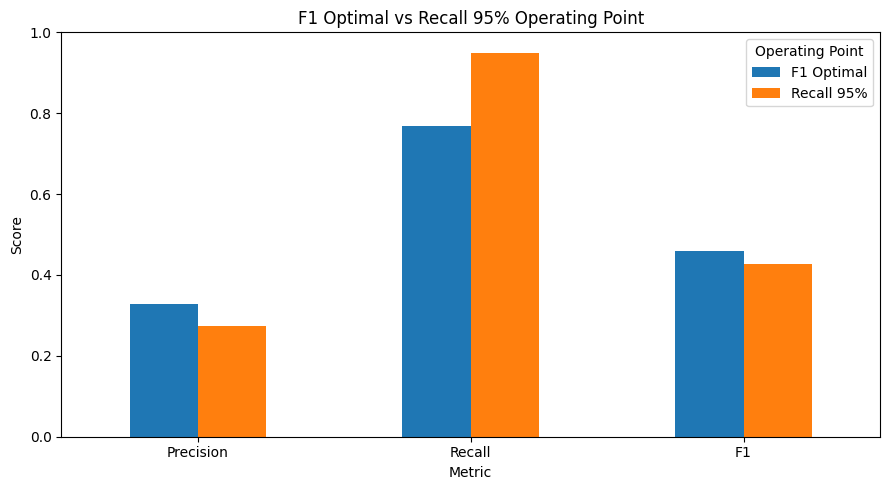

In [92]:
# ============================================================
# 22. F1 최적점 vs Recall 95% 비교 시각화
# ============================================================

comparison_plot = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1"
    ],
    "F1 Optimal": [
        valid_precision,
        valid_recall,
        valid_f1
    ],
    "Recall 95%": [
        precision_95,
        recall_95,
        f1_95
    ]
})

comparison_plot = comparison_plot.set_index("Metric")


ax = comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title(
    "F1 Optimal vs Recall 95% Operating Point"
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.legend(
    title="Operating Point"
)

plt.tight_layout()
plt.show()

Recall을 95%까지 높여도 모델의 선별 능력이 완전히 무너지지 않았으며, 관심 고객의 누락을 크게 줄일 수 있었다. 다만 상담 후보가 21,851명에서 32,300명으로 약 48% 증가하기 때문에 실제 운영 가능 여부는 상담 인력과 비용에 따라 결정해야 한다.

## 23. 최종 XGBoost Feature Importance

최종 XGBoost가 예측에 어떤 변수를 많이 활용했는지 확인한다.

XGBoost의 `Total Gain`을 기준으로 각 Feature가 전체 트리에서
분할 성능 향상에 얼마나 기여했는지 계산한다.

One-Hot Encoding으로 여러 컬럼으로 분리된 범주형 변수는
원래 변수 단위로 다시 합산하여 해석한다.

Feature Importance는 모델이 해당 변수를 얼마나 활용했는지를 의미하며,
변수와 보험 관심 여부 사이의 인과관계를 의미하지 않는다.

전처리 후 Feature 수: 216
XGBoost Feature Importance - Total Gain


,Original_Feature,Importance(%)
0,Vehicle_Damage,40.600000
1,Previously_Insured,34.850000
2,Age,11.100000
3,Policy_Sales_Channel,6.950000
4,Vehicle_Age,2.500000
5,Region_Code,2.290000
6,Annual_Premium,1.380000
7,Gender,0.250000
8,Driving_License,0.070000


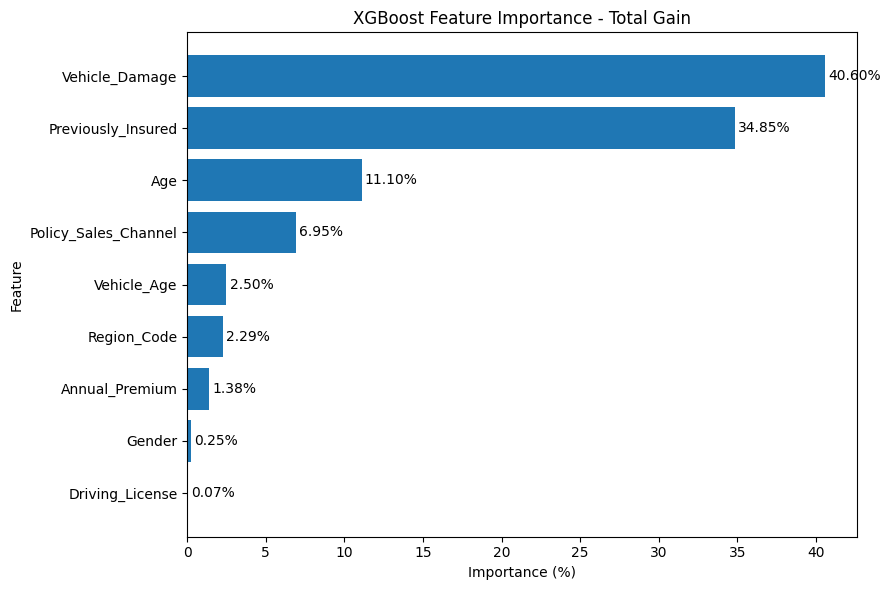

In [93]:
# ============================================================
# 23. XGBoost Feature Importance - Total Gain
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. 학습된 Preprocessor / XGBoost 추출
# ============================================================

fitted_preprocessor = final_xgb_model.named_steps["preprocessor"]
fitted_xgb = final_xgb_model.named_steps["model"]


# ============================================================
# 2. 전처리 후 Feature 이름 확인
# ============================================================

transformed_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

print(
    "전처리 후 Feature 수:",
    len(transformed_feature_names)
)


# ============================================================
# 3. XGBoost Total Gain 추출
# ============================================================

booster = fitted_xgb.get_booster()

total_gain_dict = booster.get_score(
    importance_type="total_gain"
)


# ============================================================
# 4. f0, f1 ... 을 실제 Feature 이름과 연결
# ============================================================

importance_rows = []

for i, transformed_name in enumerate(
    transformed_feature_names
):

    xgb_name = f"f{i}"

    total_gain = total_gain_dict.get(
        xgb_name,
        0
    )

    importance_rows.append({
        "Transformed_Feature": transformed_name,
        "Total_Gain": total_gain
    })


importance_detail = pd.DataFrame(
    importance_rows
)


# ============================================================
# 5. One-Hot Encoding된 Feature를 원래 변수로 복원
# ============================================================

def get_original_feature(
    transformed_name
):

    # num__Age -> Age
    if transformed_name.startswith("num__"):
        return transformed_name.replace(
            "num__",
            "",
            1
        )

    # binary__Gender -> Gender
    if transformed_name.startswith("binary__"):
        return transformed_name.replace(
            "binary__",
            "",
            1
        )

    # cat__Region_Code_28.0
    # -> Region_Code
    if transformed_name.startswith("cat__"):

        stripped = transformed_name.replace(
            "cat__",
            "",
            1
        )

        for col in categorical_cols:

            if stripped.startswith(
                col + "_"
            ):
                return col

    return transformed_name


importance_detail["Original_Feature"] = (
    importance_detail[
        "Transformed_Feature"
    ].apply(
        get_original_feature
    )
)


# ============================================================
# 6. 원래 Feature 단위 Total Gain 합산
# ============================================================

feature_importance = (
    importance_detail
    .groupby(
        "Original_Feature",
        as_index=False
    )["Total_Gain"]
    .sum()
)


# ============================================================
# 7. 비율로 변환
# ============================================================

feature_importance[
    "Importance_Ratio"
] = (
    feature_importance["Total_Gain"]
    /
    feature_importance["Total_Gain"].sum()
)


feature_importance[
    "Importance(%)"
] = (
    feature_importance[
        "Importance_Ratio"
    ] * 100
)


feature_importance = (
    feature_importance
    .sort_values(
        "Importance(%)",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 8. 결과 출력
# ============================================================

print("XGBoost Feature Importance - Total Gain")

display(
    feature_importance[
        [
            "Original_Feature",
            "Importance(%)"
        ]
    ].round(2)
)


# ============================================================
# 9. 시각화
# ============================================================

plot_data = (
    feature_importance
    .sort_values(
        "Importance(%)",
        ascending=True
    )
)

plt.figure(
    figsize=(9, 6)
)

bars = plt.barh(
    plot_data["Original_Feature"],
    plot_data["Importance(%)"]
)

plt.title(
    "XGBoost Feature Importance - Total Gain"
)

plt.xlabel(
    "Importance (%)"
)

plt.ylabel(
    "Feature"
)


for bar, value in zip(
    bars,
    plot_data["Importance(%)"]
):

    plt.text(
        value + 0.2,
        bar.get_y()
        + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center"
    )


plt.tight_layout()
plt.show()

## 24. SHAP을 이용한 최종 모델 해석

Feature Importance는 모델이 어떤 변수를 많이 사용했는지는 보여주지만,
각 변수의 값이 예측 확률을 높이는 방향인지 낮추는 방향인지는 설명하기 어렵다.

따라서 SHAP을 이용하여 각 Feature가 모델 예측에 미치는
방향과 영향 크기를 추가로 확인한다.

계산량을 줄이기 위해 Validation 데이터 중 일부를 샘플링하여 분석한다.

In [94]:
%pip install shap -q

Note: you may need to restart the kernel to use updated packages.


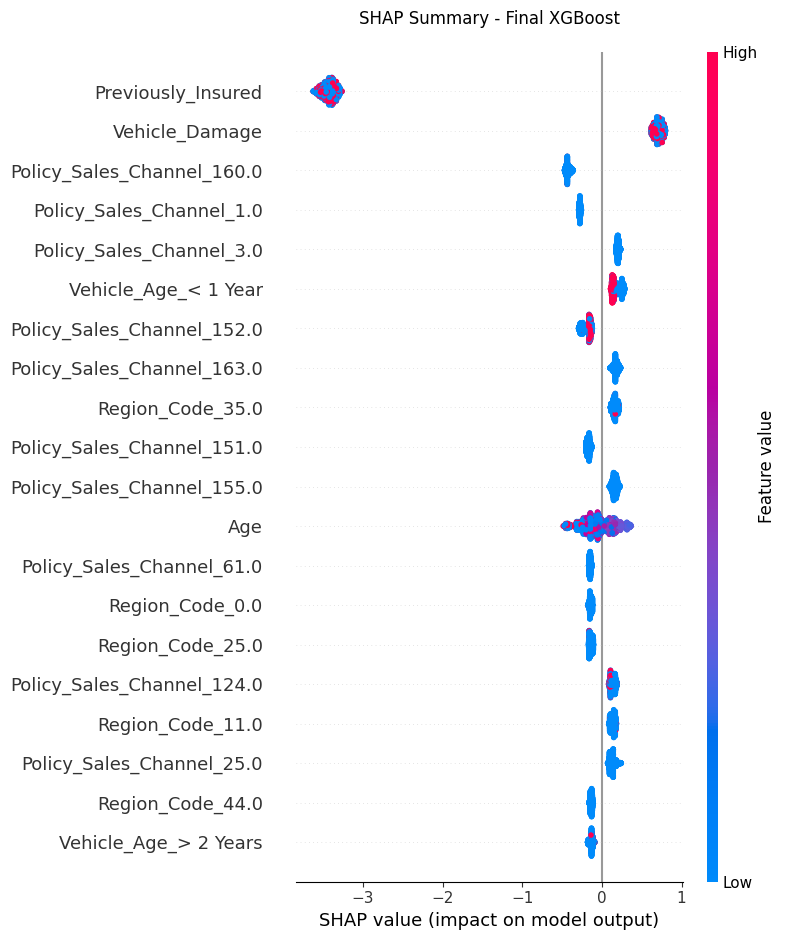

In [95]:
# ============================================================
# 24. SHAP 분석
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Validation 데이터 샘플링
# ============================================================

SHAP_SAMPLE_SIZE = 3000

X_shap = X_valid.sample(
    n=min(SHAP_SAMPLE_SIZE, len(X_valid)),
    random_state=RANDOM_STATE
)


# ============================================================
# 2. 최종 Pipeline 구성요소 추출
# ============================================================

fitted_preprocessor = (
    final_xgb_model.named_steps["preprocessor"]
)

fitted_xgb = (
    final_xgb_model.named_steps["model"]
)


# ============================================================
# 3. 전처리 적용
# ============================================================

X_shap_transformed = (
    fitted_preprocessor.transform(X_shap)
)

feature_names = (
    fitted_preprocessor.get_feature_names_out()
)


# sparse matrix이면 dense로 변환
if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = (
        X_shap_transformed.toarray()
    )


# ============================================================
# 4. SHAP 계산
# ============================================================

explainer = shap.TreeExplainer(
    fitted_xgb
)

shap_values = explainer.shap_values(
    X_shap_transformed
)


# ============================================================
# 5. Feature 이름 정리
# ============================================================

clean_feature_names = []

for name in feature_names:

    name = name.replace("num__", "")
    name = name.replace("binary__", "")
    name = name.replace("cat__", "")

    clean_feature_names.append(name)


# ============================================================
# 6. SHAP Summary Plot
# ============================================================

shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=clean_feature_names,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary - Final XGBoost",
    pad=20
)

plt.tight_layout()
plt.show()

### 24-1. 원본 변수 단위 SHAP 중요도

One-Hot Encoding으로 인해 `Policy_Sales_Channel`, `Region_Code`,
`Vehicle_Age`가 여러 개의 Feature로 분리되어 SHAP 그래프가 복잡하게 나타난다.

따라서 각 고객에 대해 동일한 원본 변수에서 파생된 SHAP 값을 합산한 뒤,
절대값의 평균을 계산하여 원래 9개 변수 단위의 전체 영향력을 비교한다.

값이 클수록 해당 변수가 최종 예측값을 크게 변화시킨다는 의미이다.

Grouped SHAP Importance


,Feature,Mean_Abs_SHAP,SHAP_Importance(%)
0,Previously_Insured,3.433900,64.145103
1,Vehicle_Damage,0.706700,13.202100
2,Policy_Sales_Channel,0.442800,8.270800
3,Region_Code,0.401200,7.494600
4,Age,0.152500,2.848000
5,Annual_Premium,0.113300,2.117200
6,Vehicle_Age,0.086000,1.607200
7,Gender,0.016200,0.303100
8,Driving_License,0.000600,0.012000


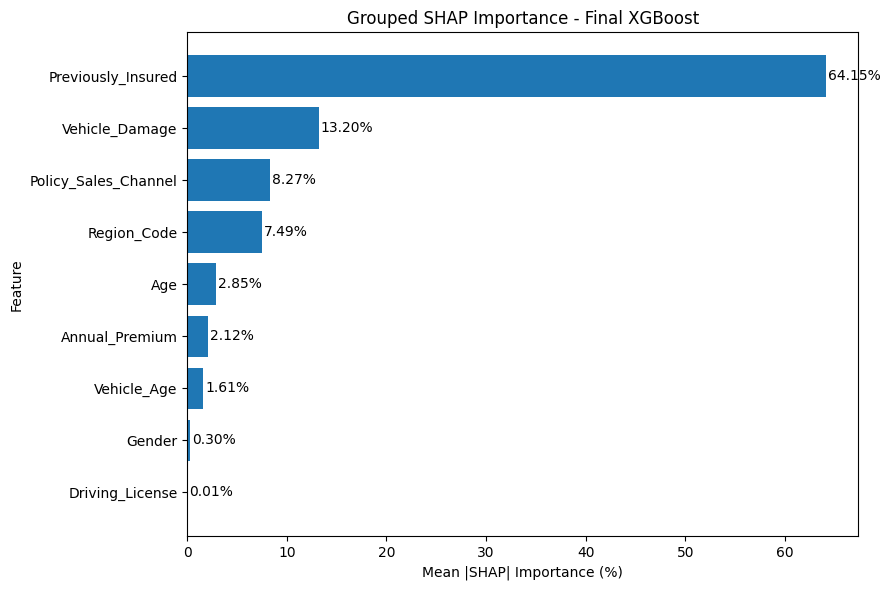

In [96]:
# ============================================================
# 24-1. 원본 변수 단위 Grouped SHAP Importance
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SHAP 값 형태 정리
# ============================================================

shap_array = np.asarray(shap_values)

# 환경에 따라 binary classification SHAP이
# 3차원으로 반환되는 경우 Positive class만 사용
if shap_array.ndim == 3:
    shap_array = shap_array[:, :, 1]


# ============================================================
# 2. 전처리된 Feature → 원본 Feature 매핑
# ============================================================

original_feature_names = []

for transformed_name in feature_names:

    if transformed_name.startswith("num__"):
        original_name = transformed_name.replace(
            "num__",
            "",
            1
        )

    elif transformed_name.startswith("binary__"):
        original_name = transformed_name.replace(
            "binary__",
            "",
            1
        )

    elif transformed_name.startswith("cat__"):

        stripped = transformed_name.replace(
            "cat__",
            "",
            1
        )

        original_name = stripped

        for col in categorical_cols:

            if stripped.startswith(col + "_"):
                original_name = col
                break

    else:
        original_name = transformed_name

    original_feature_names.append(
        original_name
    )


# ============================================================
# 3. SHAP 값을 DataFrame으로 변환
# ============================================================

shap_df = pd.DataFrame(
    shap_array,
    columns=original_feature_names
)


# ============================================================
# 4. 같은 원본 Feature의 SHAP 값 합산
#
# 예:
# Policy_Sales_Channel_1
# Policy_Sales_Channel_3
# Policy_Sales_Channel_160
#        ↓
# Policy_Sales_Channel
# ============================================================

grouped_shap = (
    shap_df
    .T
    .groupby(level=0)
    .sum()
    .T
)


# ============================================================
# 5. Mean Absolute SHAP 계산
# ============================================================

grouped_shap_importance = (
    grouped_shap
    .abs()
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

grouped_shap_importance.columns = [
    "Feature",
    "Mean_Abs_SHAP"
]


# ============================================================
# 6. 비율 계산
# ============================================================

grouped_shap_importance[
    "SHAP_Importance(%)"
] = (
    grouped_shap_importance["Mean_Abs_SHAP"]
    /
    grouped_shap_importance["Mean_Abs_SHAP"].sum()
    * 100
)


print("Grouped SHAP Importance")

display(
    grouped_shap_importance.round(4)
)


# ============================================================
# 7. 시각화
# ============================================================

plot_data = (
    grouped_shap_importance
    .sort_values(
        "SHAP_Importance(%)",
        ascending=True
    )
)

plt.figure(figsize=(9, 6))

bars = plt.barh(
    plot_data["Feature"],
    plot_data["SHAP_Importance(%)"]
)

plt.title(
    "Grouped SHAP Importance - Final XGBoost"
)

plt.xlabel(
    "Mean |SHAP| Importance (%)"
)

plt.ylabel(
    "Feature"
)


for bar, value in zip(
    bars,
    plot_data["SHAP_Importance(%)"]
):

    plt.text(
        value + 0.2,
        bar.get_y()
        + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center"
    )


plt.tight_layout()
plt.show()

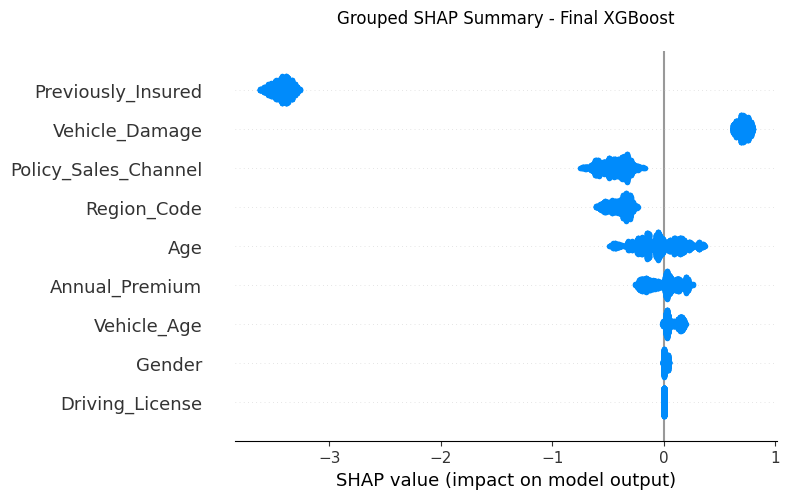

In [97]:
# ============================================================
# 24-2. 원본 9개 변수 기준 Grouped SHAP Summary Plot
# ============================================================

# 중요도 순서로 정렬
grouped_order = (
    grouped_shap
    .abs()
    .mean()
    .sort_values(ascending=False)
    .index
    .tolist()
)

grouped_shap_sorted = grouped_shap[
    grouped_order
]


# ============================================================
# Grouped SHAP Beeswarm
# ============================================================

shap.summary_plot(
    grouped_shap_sorted.values,
    feature_names=grouped_shap_sorted.columns,
    plot_type="dot",
    max_display=9,
    color_bar=False,
    show=False
)

plt.title(
    "Grouped SHAP Summary - Final XGBoost",
    pad=20
)

plt.tight_layout()
plt.show()

### SHAP 해석

원본 변수 단위로 SHAP 값을 통합한 결과,
`Previously_Insured`와 `Vehicle_Damage`가 개별 고객의 예측값에
가장 큰 영향을 미치는 변수로 나타났다.

- `Previously_Insured`는 주로 Response=0 방향으로 큰 영향을 보임
- `Vehicle_Damage`는 Response=1 방향으로 큰 영향을 보임
- `Age`, `Annual_Premium`은 고객 특성에 따라 양·음 방향의 영향이 모두 나타남
- `Gender`, `Driving_License`는 상대적으로 예측 영향이 매우 작음

단, `Policy_Sales_Channel`, `Region_Code`, `Vehicle_Age`는
One-Hot Encoding된 여러 범주의 SHAP 값을 원본 변수 단위로 합산한 결과이므로,
SHAP 값의 부호를 해당 코드값의 크기와 직접 연결하여 해석하지 않는다.

또한 `Previously_Insured`와 `Vehicle_Damage`는 서로 높은 연관성을 가지므로
개별 중요도의 절대적인 크기보다는 두 변수가 핵심 예측 변수라는 점에 초점을 맞춘다.

## 25. 최종 모델 재학습 및 Test 예측

Validation 평가까지 완료한 뒤,
동일한 XGBoost 구조와 하이퍼파라미터를 사용하여 전체 Train 데이터를 다시 학습한다.

최종 운영 Threshold는 OOF에서 결정한 F1 최적값을 사용하며,
Recall 중심 운영이 필요한 경우를 위해 Recall 95% Threshold도 함께 저장한다.

모델과 Threshold는 이후 재사용할 수 있도록 `joblib` 형식으로 저장한다.

In [98]:
# ============================================================
# 25. 최종 모델 전체 Train 재학습 + Test 예측 + 저장
# ============================================================

from sklearn.base import clone
import joblib
import pandas as pd


# ============================================================
# 1. 최종 모델 복제
# ============================================================

production_model = clone(
    final_xgb_model
)


# ============================================================
# 2. 전체 Train 데이터로 재학습
# ============================================================

production_model.fit(
    X,
    y
)

print("전체 Train 데이터 학습 완료")


# ============================================================
# 3. Test 확률 예측
# ============================================================

test_prob = production_model.predict_proba(
    X_test_final
)[:, 1]


# ============================================================
# 4. F1 최적 Threshold 적용
# ============================================================

test_pred_f1 = (
    test_prob >= final_threshold
).astype(int)


# ============================================================
# 5. Recall 95% Threshold 적용
# ============================================================

test_pred_recall95 = (
    test_prob >= threshold_95
).astype(int)


# ============================================================
# 6. 제출용 파일 생성
# ============================================================

submission_f1 = pd.DataFrame({
    "id": test["id"],
    "Response": test_pred_f1
})

submission_recall95 = pd.DataFrame({
    "id": test["id"],
    "Response": test_pred_recall95
})

submission_probability = pd.DataFrame({
    "id": test["id"],
    "Response_Probability": test_prob
})


# ============================================================
# 7. CSV 저장
# ============================================================

submission_f1.to_csv(
    "submission_f1_optimal.csv",
    index=False
)

submission_recall95.to_csv(
    "submission_recall95.csv",
    index=False
)

submission_probability.to_csv(
    "submission_probability.csv",
    index=False
)


# ============================================================
# 8. 모델 / Threshold 저장
# ============================================================

joblib.dump(
    production_model,
    "final_xgboost_model_no_vintage.pkl"
)

joblib.dump(
    final_threshold,
    "final_xgboost_threshold_f1.pkl"
)

joblib.dump(
    threshold_95,
    "final_xgboost_threshold_recall95.pkl"
)


# ============================================================
# 9. 저장 결과 확인
# ============================================================

print("\n===== 저장 완료 =====")

print(
    f"F1 Optimal Threshold : "
    f"{final_threshold:.6f}"
)

print(
    f"Recall 95% Threshold : "
    f"{threshold_95:.6f}"
)

print(
    "\nTest 예측 관심 고객 수"
)

print(
    f"F1 Optimal : "
    f"{test_pred_f1.sum():,}"
)

print(
    f"Recall 95% : "
    f"{test_pred_recall95.sum():,}"
)

print("\n저장 파일")
print("- final_xgboost_model_no_vintage.pkl")
print("- final_xgboost_threshold_f1.pkl")
print("- final_xgboost_threshold_recall95.pkl")
print("- submission_f1_optimal.csv")
print("- submission_recall95.csv")
print("- submission_probability.csv")

전체 Train 데이터 학습 완료

===== 저장 완료 =====
F1 Optimal Threshold : 0.222612
Recall 95% Threshold : 0.099649

Test 예측 관심 고객 수
F1 Optimal : 36,524
Recall 95% : 54,067

저장 파일
- final_xgboost_model_no_vintage.pkl
- final_xgboost_threshold_f1.pkl
- final_xgboost_threshold_recall95.pkl
- submission_f1_optimal.csv
- submission_recall95.csv
- submission_probability.csv


In [ ]:
import joblib

model_check = joblib.load(
    "final_xgboost_model_no_vintage.pkl"
)

threshold_f1_check = joblib.load(
    "final_xgboost_threshold_f1.pkl"
)

threshold_95_check = joblib.load(
    "final_xgboost_threshold_recall95.pkl"
)

print("모델 로드 성공")
print("F1 Threshold:", threshold_f1_check)
print("Recall 95% Threshold:", threshold_95_check)

모델 로드 성공
F1 Threshold: 0.22261247
Recall 95% Threshold: 0.099648535


## 26. 최종 결론 및 향후 개선 방향

### 최종 모델
초기 모델 비교 결과 XGBoost가 ROC-AUC와 AP에서 가장 우수한 성능을 보여 최종 모델로 선정하였다.

EDA와 통계 검정을 통해 `Vintage`는 보험 관심 여부와의 연관성이 거의 없음을 확인하여 최종 입력 변수에서 제외하였고,
9개 Feature를 사용하여 XGBoost를 다시 학습하였다.

OOF 예측에서 F1 Score가 최대가 되는 Threshold를 선택한 결과:

- Threshold: **0.2226**
- Precision: **32.85%**
- Recall: **76.84%**
- F1 Score: **0.4602**
- ROC-AUC: **0.8587**
- AP: **0.3721**

Validation 데이터에서도 OOF와 유사한 성능을 보여 Threshold가 비교적 안정적으로 일반화됨을 확인하였다.


### Recall 중심 운영 실험
보험 관심 고객을 최대한 놓치지 않는 상황을 가정하여
Recall 95%를 목표로 Threshold를 추가로 설정하였다.

| 운영 기준 | Threshold | Precision | Recall | F1 | 상담 후보 |
|---|---:|---:|---:|---:|---:|
| F1 최적 | 0.2226 | 32.85% | 76.84% | 0.4602 | 21,851명 |
| Recall 95% | 0.0996 | 27.47% | 94.99% | 0.4262 | 32,300명 |

Recall 중심 운영에서는 실제 관심 고객을 놓친 FN이
**2,164명 → 468명**으로 크게 감소하였다.

반면 상담 후보 고객은
**21,851명 → 32,300명**으로 증가하고 Precision과 F1은 감소하였다.

따라서 하나의 Threshold가 항상 최적이라고 볼 수 없으며,
실제 비즈니스 환경에서는 상담 가능 인력과 비용에 따라 운영 Threshold를 조정할 필요가 있다.


### 모델 해석
XGBoost Total Gain 기준으로는 다음 변수의 중요도가 높게 나타났다.

1. `Vehicle_Damage`
2. `Previously_Insured`
3. `Age`
4. `Policy_Sales_Channel`

Grouped SHAP 분석에서는 `Previously_Insured`와 `Vehicle_Damage`가
개별 고객의 예측값에 가장 큰 영향을 주는 핵심 변수로 확인되었다.

단, Feature Importance와 SHAP은 모델 내부의 예측 기여도를 나타내며
변수와 보험 관심 여부 사이의 인과관계를 의미하지 않는다.


### 한계점
현재 데이터에는 실제 상담 비용, 상담 가능 인력,
캠페인 예산 및 실제 가입으로 이어졌을 때의 수익 정보가 포함되어 있지 않다.

따라서 현재 Threshold는 모델 성능 지표를 기준으로 비교한 것이며,
비즈니스 관점에서의 최적 Threshold라고 단정할 수 없다.

또한 모델은 과거 데이터 패턴을 기반으로 학습되었으므로
향후 고객 특성이나 시장 환경이 변화하면 성능이 달라질 수 있다.


### 향후 개선 방향
실제 운영 데이터가 확보된다면 다음과 같은 방식으로 확장할 수 있다.

- 고객 1명당 상담 비용 산정
- 전체 캠페인 예산 또는 상담 가능 인원 설정
- 예산 제약 내에서 Recall이 최대가 되는 Threshold 탐색
- 실제 계약 전환율과 고객당 기대수익을 반영한 비용-효익 분석
- 운영 이후 발생한 신규 데이터를 활용한 주기적 재학습

즉, 최종 Threshold는 고정된 값이 아니라
**기업의 상담 자원과 캠페인 예산에 따라 조정되는 운영 정책**으로 활용할 수 있다.

In [2]:
import pandas as pd

# 예측 확률 결과 불러오기
result = pd.read_csv("submission_probability.csv")

# 관심 확률 높은 순으로 정렬
top_customers = (
    result
    .sort_values(
        "Response_Probability",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

# 순위 추가
top_customers.insert(
    0,
    "Rank",
    range(1, len(top_customers) + 1)
)

top_customers

,Rank,id,Response_Probability
0,1,483021,0.651738
1,2,501937,0.645499
2,3,466697,0.645143
3,4,472673,0.644196
4,5,453802,0.643543
5,6,394143,0.639008
6,7,395476,0.638271
7,8,469680,0.635589
8,9,457957,0.633591
9,10,488260,0.632144
